# Classification de l'espèce d'un iris : KNN vs Arbre de décision

**Durée estimée : 1h**

## Mise en situation
Vous êtes data scientist chez **FloraLab**, un laboratoire de botanique. La direction veut un outil qui reconnaît **automatiquement l'espèce d'un iris** (Setosa, Versicolor, Virginica) à partir de quatre mesures, sans expert.


## Comment utiliser ce notebook
- Chaque section contient une **explication** (cellule texte) suivie d'une **cellule de code à compléter**.
- Les lignes `# TODO` indiquent ce qu'il faut écrire, avec un **indice** sur la fonction à utiliser.
- Les cellules **Interprétation** sont à remplir avec vos propres mots : c'est ce qui est évalué en plus du code.
- Exécutez les cellules **dans l'ordre**.

## 0. Imports et configuration
*Cette cellule est déjà remplie. Ajoutez des imports si nécessaire.*

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 1. Exploration et analyse des données (EDA)

### 1.1 Chargement et structure
**But :** comprendre la forme.
**À faire :** llire le dataset, puis afficher `head()`, `shape`, `info()` et `describe()`.



In [11]:
df = sns.load_dataset("iris")
# TODO 1 : afficher head(), shape, info() et describe()
print(df.head())
print(df.shape)
print(df.info())
print(df.describe())

   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa
(150, 5)
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.2 KB
None
       sepal_length  sepal_width  petal_length  petal_width
count    150.000000   150.000000    150.000000   150.000000
mean       5.843333     3.057333      3.

### 1.2 Types de variables, valeurs manquantes et doublons
**But :** repérer les problèmes de qualité.
**À faire :** identifier variables numériques et catégorielles, compter les valeurs manquantes et les doublons, vérifier qu'aucune mesure n'est négative ou nulle.


In [12]:
# TODO : types, valeurs manquantes, doublons, valeurs impossibles
print(df.dtypes)
print(df.isnull().sum())
print(df.duplicated().sum())
print(df.min())
print(df.max())

sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species             str
dtype: object
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64
1
sepal_length       4.3
sepal_width        2.0
petal_length       1.0
petal_width        0.1
species         setosa
dtype: object
sepal_length          7.9
sepal_width           4.4
petal_length          6.9
petal_width           2.5
species         virginica
dtype: object


### 1.3 Équilibre des classes
**But :** savoir si l'accuracy sera une métrique fiable.
**À faire :** compter le nombre de fleurs par espèce et l'afficher dans un graphique en barres.


species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


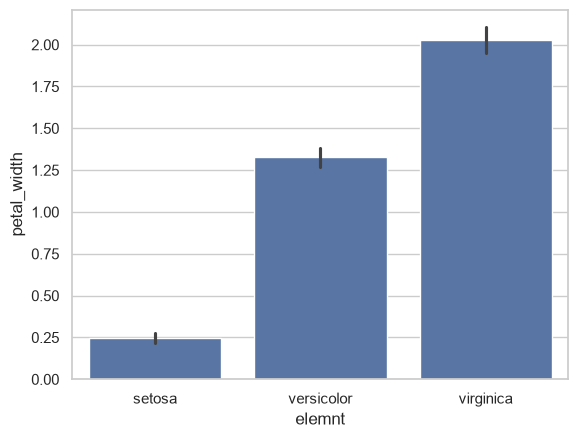

In [13]:
# TODO : value_counts + countplot ou graphique en barres
print(df['species'].value_counts())

sns.barplot(df ,x=df["species"],y=df["petal_width"])
plt.xlabel("elemnt")
plt.show()   

### 1.4 Distributions des variables
**But :** comprendre la forme de chaque mesure.
**À faire :** tracer un histogramme et un boxplot pour une variable(s) numérique(s), puis un boxplot **par espèce**.


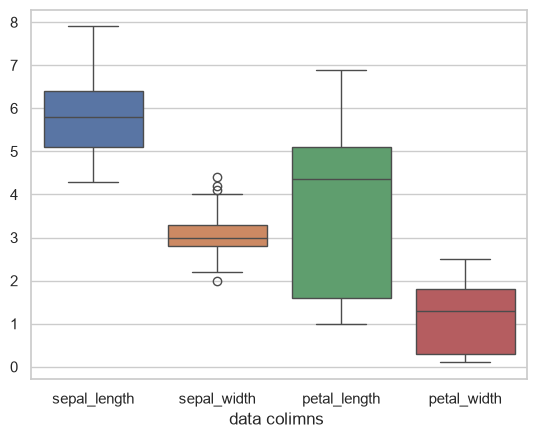

In [14]:
# TODO : histogrammes
# for el in df:
#   df.hist(column=el)
#   plt.xlabel(f"showing elemnt column")
#   plt.show()
# TODO : boxplots par espèce
sns.boxplot(df )
plt.xlabel("data colimns ")
plt.show()

### 1.5 Corrélations
**But :** repérer les variables redondantes.
**À faire :** calculer la matrice de corrélation des 4 mesures et l'afficher en heatmap.


In [15]:
# TODO : matrice de corrélation + heatmap
df[["sepal_length","sepal_width","petal_length","petal_width"    ]].corr()


,sepal_length,sepal_width,petal_length,petal_width
sepal_length,1.000000,-0.117570,0.871754,0.817941
sepal_width,-0.117570,1.000000,-0.428440,-0.366126
petal_length,0.871754,-0.428440,1.000000,0.962865
petal_width,0.817941,-0.366126,0.962865,1.000000


## 2. Nettoyage des données
**But :** obtenir un jeu de données fiable.
**À faire :**
1. Traiter les valeurs manquantes (s'il y en a).
2. Supprimer les doublons **seulement si c'est justifié**.
3. Corriger les valeurs impossibles.
4. Vérifier la qualité après nettoyage (shape, doublons, valeurs manquantes).


In [16]:
# TODO : nettoyage (doublons, valeurs manquantes, incohérences)
df.drop_duplicates()
print(df.duplicated().sum())
print(df.isna().sum())


# TODO : vérification après nettoyage

1
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


**Justification de vos décisions de nettoyage :**

...

## 3. Préparation des données
**But :** séparer ce qu'on veut prédire de ce qui sert à prédire.
**À faire :**
- Définir `y` (la cible : l'espèce).
- Définir `X` (les 4 mesures).
- Lister les variables numériques, nominales et ordinales.
- Écarter les identifiants ou variables non pertinentes.

In [17]:
# TODO : définir y
y=df[["species"]]
x=df[["sepal_length","petal_width",  "sepal_width" ,"petal_length"] ]
# TODO : définir X
print(y)
# TODO : créer la liste num_features (variables numériques)

       species
0       setosa
1       setosa
2       setosa
3       setosa
4       setosa
..         ...
145  virginica
146  virginica
147  virginica
148  virginica
149  virginica

[150 rows x 1 columns]


## 4. Séparation Train / Test
**But :** garder un jeu de test totalement indépendant pour l'évaluation finale.
**À faire :** séparer en 80 % / 20 % avec `random_state` et `stratify=y`, puis vérifier la répartition des espèces dans chaque ensemble.

> Le split se fait **avant** tout apprentissage de transformation (sinon : fuite de données).

In [18]:
# TODO : X_train, X_test, y_train, y_test = train_test_split(...)
X_train, X_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=42)
# TODO : afficher la répartition des espèces dans y_train et y_test
print(y_test,y_train,X_test,X_train)

        species
73   versicolor
18       setosa
118   virginica
78   versicolor
76   versicolor
31       setosa
64   versicolor
141   virginica
68   versicolor
82   versicolor
110   virginica
12       setosa
36       setosa
9        setosa
19       setosa
56   versicolor
104   virginica
69   versicolor
55   versicolor
132   virginica
29       setosa
127   virginica
26       setosa
128   virginica
131   virginica
145   virginica
108   virginica
143   virginica
45       setosa
30       setosa         species
22       setosa
15       setosa
65   versicolor
11       setosa
42       setosa
..          ...
71   versicolor
106   virginica
14       setosa
92   versicolor
102   virginica

[120 rows x 1 columns]      sepal_length  petal_width  sepal_width  petal_length
73            6.1          1.2          2.8           4.7
18            5.7          0.3          3.8           1.7
118           7.7          2.3          2.6           6.9
78            6.0          1.5          2.9           4.

## 5. Prétraitement
**But :** préparer les transformations (sans encore les apprendre).
**À faire :**
- Créer un `ColumnTransformer` qui applique sur les variables numériques : `SimpleImputer(strategy='median')` puis `StandardScaler()`.
- Justifier l'absence d'`OneHotEncoder` et d'`OrdinalEncoder`.

In [19]:
# TODO : numeric_transformer = Pipeline([...])
# TODO : 
caractere=df[["species"]]
print(caractere)
num=df[["sepal_length","petal_width",  "sepal_width" ,"petal_length"]]
preprocessor = ColumnTransformer([
    ("num",StandardScaler(),num)
    ,("caractere",OneHotEncoder(),caractere)
])

       species
0       setosa
1       setosa
2       setosa
3       setosa
4       setosa
..         ...
145  virginica
146  virginica
147  virginica
148  virginica
149  virginica

[150 rows x 1 columns]


## 6. Construction des pipelines
**But :** enchaîner prétraitement + modèle dans un seul objet, pour éviter toute fuite de données pendant la validation croisée.
**À faire :** créer ** le pipeline ** :
- `pipe_knn` : preprocessor + `KNeighborsClassifier()`

> Dans un `Pipeline`, donnez des noms aux étapes (par ex. `'prep'` et `'model'`) : vous en aurez besoin pour la grille d'hyperparamètres (`model__n_neighbors`).

In [20]:
# TODO : pipe_knn = Pipeline([...])
pipe_knn = Pipeline([("prep",preprocessor),("model",KNeighborsClassifier(n_neighbors=3))])

## 7. Entraînement
**But :** obtenir une première version du modèle avec les hyperparamètres par défaut.

- **Algorithme 1 : KNN** — classe une fleur selon ses voisins les plus proches (modèle de référence).

**À faire :** entraîner le pipeline sur `X_train`, `y_train` et afficher l'accuracy sur le train.

In [21]:
# TODO : fit de pipe_knn
     
pipe_knn.fit(X_train,y_train)
# TODO : 


ValueError: No valid specification of the columns. Only a scalar, list or slice of all integers or all strings, or boolean mask is allowed

## 8. Validation croisée
**But :** estimer la performance de façon fiable.
**À faire :**
- Créer `cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)`.
- Calculer les scores de chaque pipeline avec `cross_val_score` (métrique `accuracy`, puis `f1_macro`).
- Afficher la **moyenne** des scores.


In [ ]:
# TODO : cv = StratifiedKFold(...)
# TODO : scores accuracy et f1_macro pour pipe_knn
# TODO : afficher moyenne

## 9. Optimisation des hyperparamètres (GridSearchCV)
**But :** trouver les meilleurs réglages.
**À faire :** définir une grille pour ton pipeline, lancer `GridSearchCV(..., cv=cv, scoring='f1_macro')` et afficher `best_params_` et `best_score_`.

Grilles suggérées :
- **KNN** : `model__n_neighbors` (2 à 5), `model__weights` (`uniform`, `distance`), `model__p` (1, 2).
> Le préfixe `model__` correspond au nom de l'étape dans votre pipeline.
> Le GridSearch ne doit utiliser que `X_train` et `y_train`.

In [ ]:
# TODO : param_grid_knn
# TODO : grid_knn = GridSearchCV(...) puis fit sur le train
# TODO : afficher best_params_ et best_score_

## 10. Évaluation sur le jeu de test
**But :** mesurer la performance réelle sur des données jamais vues.
**À faire :** pour chaque meilleur modèle (`best_estimator_`) :
1. Prédire sur `X_test`.
2. Calculer accuracy, précision (macro), rappel (macro) et F1 (macro).
3. Afficher la **matrice de confusion** et le `classification_report`.
4. Donner les valeurs ( TP , FP , TN , FN) pour chaque classe .

Rappel des métriques :
- **Accuracy** : proportion de fleurs bien classées.
- **Précision** : parmi les fleurs prédites d'une espèce, combien le sont vraiment.
- **Rappel** : parmi les fleurs réellement d'une espèce, combien sont retrouvées.
- **F1 macro** : moyenne du F1 des trois espèces, à égalité.

> Le jeu de test ne doit servir qu'ici, une seule fois.

In [ ]:
# TODO : best_knn = grid_knn.best_estimator_
# TODO : prédictions sur X_test
# TODO : métriques (accuracy, precision, recall, f1 avec average='macro')
# TODO : matrices de confusion (ConfusionMatrixDisplay.from_estimator)
# TODO : classification_report